# LKS AI — Prediksi Risiko Stroke dengan Logistic Regression (dari nol)

**Tujuan:** alat **skrining** untuk menandai pasien yang perlu diperiksa lebih lanjut karena berisiko stroke.
**Algoritma:** Logistic Regression ditulis sendiri dengan numpy (tanpa scikit-learn).
**Library:** numpy, pandas, matplotlib, seaborn, json, os (+ tkinter untuk GUI).
**Struktur kode:** OOP. Tiga class (`Preprocessor`, `LogisticRegression`, `StrokeModel`) ditulis sekali di `model_lr.py`, lalu dipakai oleh notebook **dan** GUI.

| Modul | Isi | Bobot |
|---|---|---|
| A | Data preparation & EDA | 20 |
| B | Split, preprocessing, Logistic Regression dari nol | 25 |
| C | Evaluasi, perbaikan, simpan model | 20 |
| D | Uji data baru dengan GUI (`gui_stroke_lr.py`) | 25 |

**Tiga aturan yang dipegang di seluruh notebook:**
1. **Cek label dulu** sebelum apa pun.
2. **Split dulu, baru hitung statistik.** Median, mean, dan std dihitung dari data latih saja.
3. **Data uji hanya dipakai satu kali**, di akhir. Semua pilihan (threshold dan lain-lain) dibuat di data validasi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json, os

SEED = 42
TARGET = 'stroke'
pd.set_option('display.max_columns', None)

---
# Modul A — Data Preparation & EDA
## A.1 Memuat data

In [2]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


| Jenis | Kolom |
|---|---|
| Label | `stroke` (0 = tidak, 1 = ya) |
| Numerik | `age`, `avg_glucose_level`, `bmi` |
| Biner (0/1) | `hypertension`, `heart_disease` |
| Kategorikal | `gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status` |
| Bukan fitur | `id`: nomor urut pasien, tidak ada hubungannya dengan stroke |

## A.2 Cek label PERTAMA KALI

stroke
0    4861
1     249
Name: count, dtype: int64

Persentase stroke: 4.87%


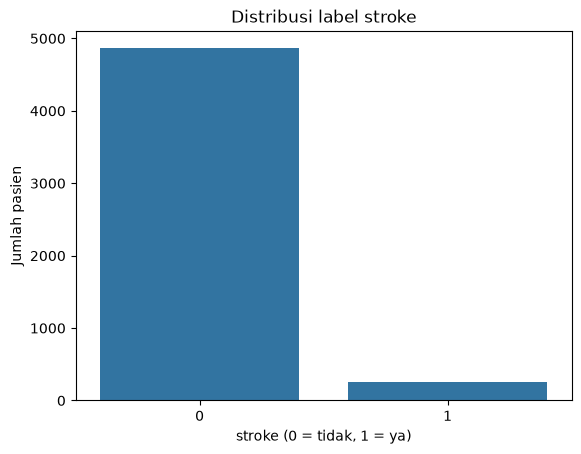

In [4]:
print(df[TARGET].value_counts())
print(f"\nPersentase stroke: {df[TARGET].mean() * 100:.2f}%")

sns.countplot(x=TARGET, data=df)
plt.title('Distribusi label stroke')
plt.xlabel('stroke (0 = tidak, 1 = ya)')
plt.ylabel('Jumlah pasien')
plt.show()

**Insight 1 — Data sangat tidak seimbang (±95 : 5).** Hanya 249 dari 5.110 pasien (4,87%) yang stroke. Model yang selalu menjawab *tidak stroke* sudah akurat 95% tanpa belajar apa pun.

Implikasinya ke seluruh notebook:
- **Accuracy bukan metrik utama** → pakai recall dan F2.
- Split harus **stratified**.
- Model perlu **class weight**.

## A.3 Audit kualitas data

In [5]:
print('Missing per kolom:')
print(df.isna().sum()[df.isna().sum() > 0])
print('\nDuplikat baris :', df.duplicated().sum())
print('Duplikat id    :', df['id'].duplicated().sum())

for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f'\n{col}:', df[col].value_counts().to_dict())

Missing per kolom:
bmi    201
dtype: int64

Duplikat baris : 0
Duplikat id    : 0

gender: {'Female': 2994, 'Male': 2115, 'Other': 1}

ever_married: {'Yes': 3353, 'No': 1757}

work_type: {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}

Residence_type: {'Urban': 2596, 'Rural': 2514}

smoking_status: {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}


In [6]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [7]:
print('BMI > 60       :', (df['bmi'] > 60).sum(), 'baris (maks', df['bmi'].max(), ')')
print('Usia < 1 tahun :', (df['age'] < 1).sum(), 'baris (bayi)')

# Apakah BMI yang kosong itu acak? Dan apa akibatnya kalau di-drop?
kosong = df['bmi'].isna()
print(f"\nStroke saat BMI kosong : {df.loc[kosong, TARGET].mean() * 100:.1f}%")
print(f"Stroke saat BMI terisi : {df.loc[~kosong, TARGET].mean() * 100:.1f}%")
hilang = df.loc[kosong, TARGET].sum() / df[TARGET].sum()
print(f"Jika dropna: {kosong.mean() * 100:.1f}% baris hilang, tapi {hilang * 100:.1f}% kasus STROKE ikut hilang")

BMI > 60       : 13 baris (maks 97.6 )
Usia < 1 tahun : 43 baris (bayi)

Stroke saat BMI kosong : 19.9%
Stroke saat BMI terisi : 4.3%
Jika dropna: 3.9% baris hilang, tapi 16.1% kasus STROKE ikut hilang


**Log keputusan cleaning**

| Masalah | Bukti | Tindakan | Alasan |
|---|---|---|---|
| `id` | nomor urut unik | **drop kolom** | tidak ada hubungannya dengan stroke |
| `gender = Other` | 1 baris | **drop baris** | 1 contoh tidak bisa dipelajari |
| `bmi` kosong | 201 baris | **jangan di-drop**; isi **median data latih** di Modul B | drop = kehilangan **16% kasus stroke** (kelas yang paling langka); isi setelah split agar tidak *leakage* |
| `bmi` > 60 | 13 baris, maks 97,6 | **biarkan** | mungkin terjadi (obesitas ekstrem); z-score tidak memotongnya, dan efeknya kecil karena BMI fitur lemah |
| `smoking_status = Unknown` | 30% data | **kategori sendiri** | terlalu banyak untuk dibuang |
| usia < 1 | 43 baris | **biarkan** | valid: bayi |
| Duplikat | 0 | — | — |

In [8]:
df = df.drop(columns=['id'])                              # WAJIB di-assign ulang
df = df[df['gender'] != 'Other'].reset_index(drop=True)
print('Ukuran setelah cleaning:', df.shape)
print('Kolom:', df.columns.tolist())                       # verifikasi id sudah hilang

Ukuran setelah cleaning: (5109, 11)
Kolom: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


## A.4 Exploratory Data Analysis

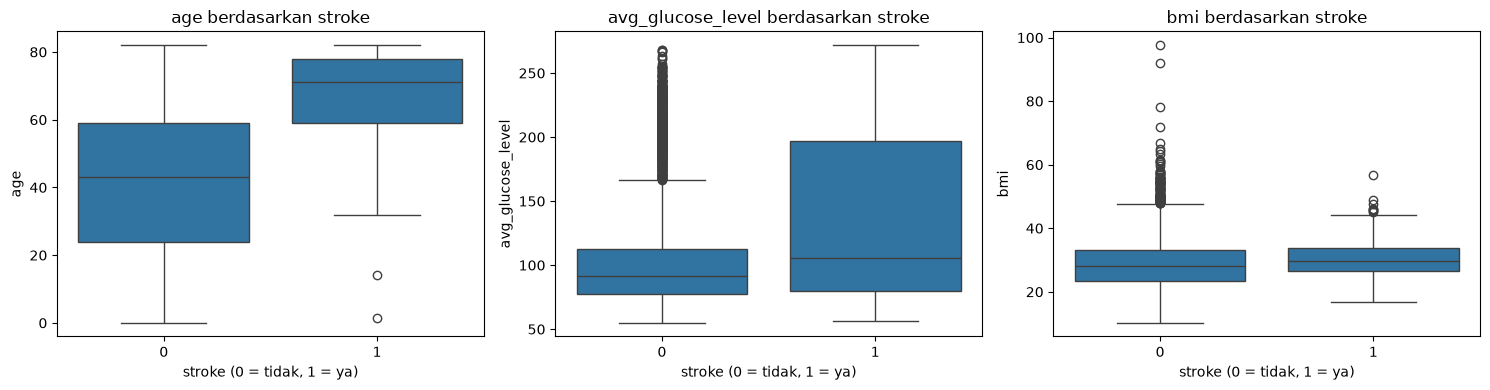

         age  avg_glucose_level   bmi
stroke                               
0       43.0             91.465  28.0
1       71.0            105.220  29.7


In [9]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax)
    ax.set_title(f'{col} berdasarkan stroke')
    ax.set_xlabel('stroke (0 = tidak, 1 = ya)')
plt.tight_layout()
plt.show()
print(df.groupby(TARGET)[num_cols].median())

**Insight 2 — Usia pembeda terkuat.** Median usia 71 tahun (stroke) vs 43 tahun (tidak). Gula darah juga lebih tinggi (105 vs 91). BMI hampir sama (29,7 vs 28,0), jadi diduga fitur lemah.
Titik di atas whisker gula darah (±550 pasien) adalah **outlier statistik, bukan data salah**: itu kelompok gula darah tinggi (kemungkinan diabetes), jadi dipertahankan.

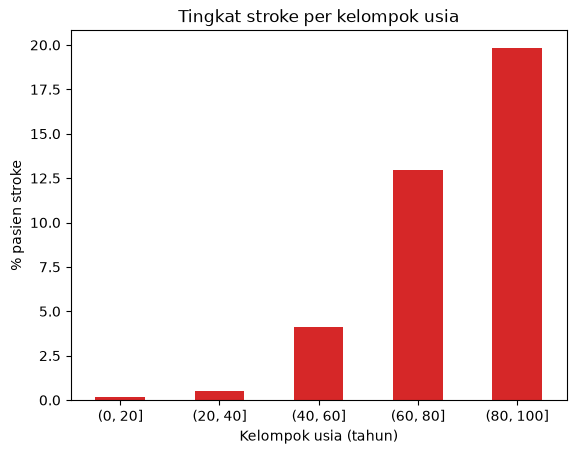

age
(0, 20]       0.2
(20, 40]      0.5
(40, 60]      4.1
(60, 80]     13.0
(80, 100]    19.8
Name: stroke, dtype: float64


In [10]:
kelompok_usia = pd.cut(df['age'], bins=[0, 20, 40, 60, 80, 100])
tingkat = df.groupby(kelompok_usia, observed=True)[TARGET].mean() * 100
tingkat.plot(kind='bar', color='tab:red')
plt.title('Tingkat stroke per kelompok usia')
plt.xlabel('Kelompok usia (tahun)')
plt.ylabel('% pasien stroke')
plt.xticks(rotation=0)
plt.show()
print(tingkat.round(1))

**Insight 3 — Risiko naik tajam seiring usia:** <1% di bawah 40 tahun → 4% (40–60) → 13% (60–80) → ±20% (80+). Kenaikannya selalu searah (monoton), jadi logistic regression bisa menangkapnya lewat satu koefisien usia yang positif.

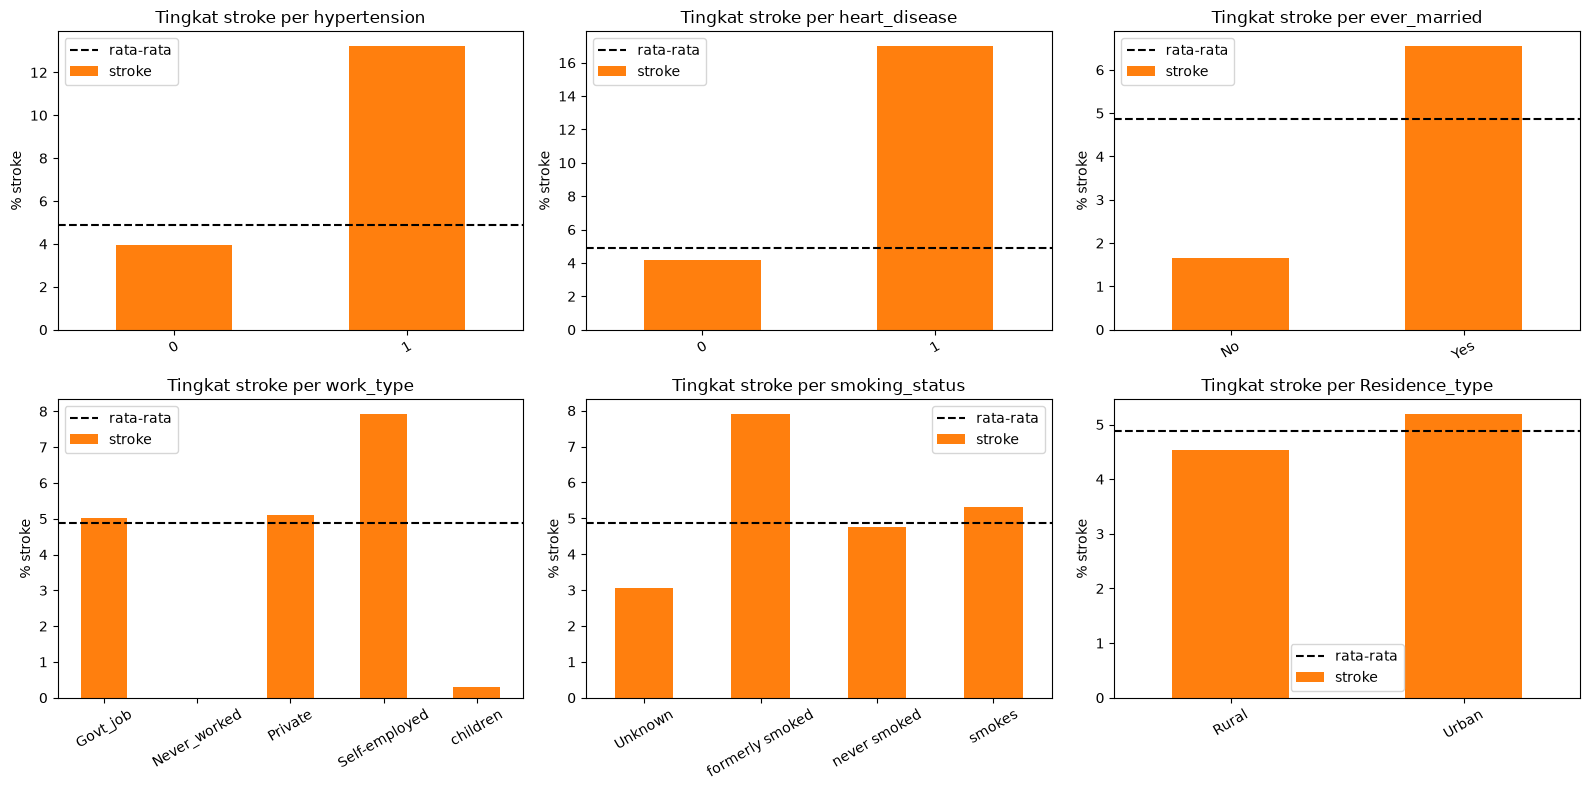

In [11]:
kat_cols = ['hypertension', 'heart_disease', 'ever_married', 'work_type', 'smoking_status', 'Residence_type']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), kat_cols):
    rate = df.groupby(col)[TARGET].mean() * 100
    rate.plot(kind='bar', ax=ax, color='tab:orange')
    ax.axhline(df[TARGET].mean() * 100, color='black', linestyle='--', label='rata-rata')
    ax.set_title(f'Tingkat stroke per {col}')
    ax.set_ylabel('% stroke')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()

**Insight 4 — Riwayat penyakit memperbesar risiko.** Hipertensi 13,3% vs 4,0% (≈3,3×), penyakit jantung 17,0% vs 4,2% (≈4×). Tempat tinggal hampir tidak berpengaruh (5,2% vs 4,5%).

Status menikah terlihat berpengaruh besar (6,6% vs 1,7%). Tapi apakah itu efek asli, atau hanya karena orang yang sudah menikah lebih tua? Cek di bawah.

In [12]:
print('Median usia per status menikah :', df.groupby('ever_married')['age'].median().to_dict())

lansia = df[df['age'] >= 60]          # kendalikan usia: bandingkan sesama lansia saja
print('\nTingkat stroke KHUSUS usia >= 60 tahun:')
for col in ['ever_married', 'smoking_status']:
    t = lansia.groupby(col)[TARGET].agg(['mean', 'count'])
    print(f'  {col}:', {k: f"{v['mean'] * 100:.1f}% (n={int(v['count'])})" for k, v in t.iterrows()})

Median usia per status menikah : {'No': 18.0, 'Yes': 54.0}

Tingkat stroke KHUSUS usia >= 60 tahun:
  ever_married: {'No': '19.6% (n=107)', 'Yes': '12.6% (n=1269)'}
  smoking_status: {'Unknown': '11.9% (n=260)', 'formerly smoked': '13.9% (n=388)', 'never smoked': '13.2% (n=537)', 'smokes': '13.1% (n=191)'}


**Insight 5 — Confounding usia.** Median usia yang sudah menikah 54 tahun vs 18 tahun yang belum. Kalau hanya membandingkan sesama lansia (≥ 60):
- efek menikah **berbalik** (belum menikah 19,6% vs menikah 12,6%; tapi n belum menikah kecil, 107 orang);
- semua kategori merokok hampir sama (11,9%–13,9%).

Artinya perbedaan besar di grafik sebelumnya sebagian besar adalah **efek usia yang menumpang**. Dampaknya ke model: koefisien `ever_married` bisa bernilai negatif, dan itu **bukan error** (dibahas di Modul C).

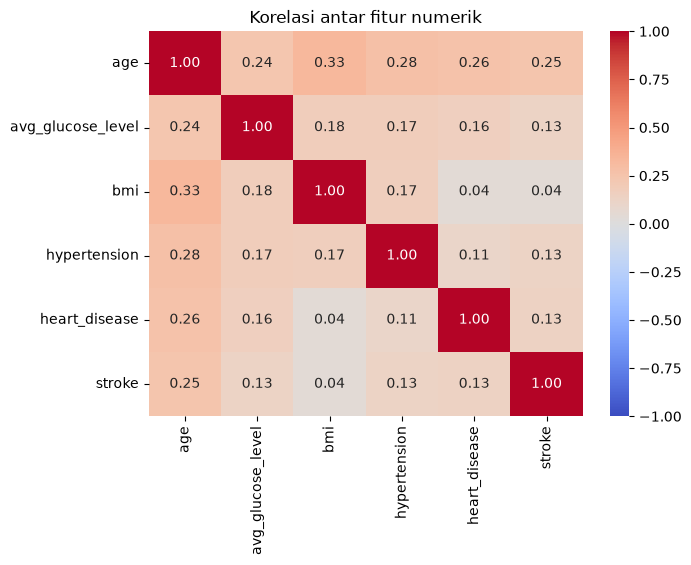

In [13]:
corr = df[num_cols + ['hypertension', 'heart_disease', TARGET]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar fitur numerik')
plt.show()

**Insight 6 — Korelasi dengan label lemah** (tertinggi usia 0,25). Ini wajar untuk label yang jarang. Antar-fitur juga tidak ada korelasi yang tinggi (maks 0,33), jadi tidak ada masalah multikolinearitas untuk regresi logistik.

In [14]:
df.to_csv('df_clean.csv', index=False)
print('Tersimpan: df_clean.csv', df.shape, '| BMI kosong', df['bmi'].isna().sum(), '-> diisi di Modul B')

Tersimpan: df_clean.csv (5109, 11) | BMI kosong 201 -> diisi di Modul B


---
# Modul B — Klasifikasi
## B.1 Split data: kenapa 80/20 (dengan validasi dari data latih), bukan 70/15/15?

Dua-duanya punya **data validasi** terpisah dari data uji, dan itulah yang paling penting. Bedanya:

| | 70 / 15 / 15 | **80 / 20 + validasi dari data latih** |
|---|---|---|
| Kasus stroke di data uji | ±37 | **±50** |
| 1 pasien stroke = berapa % recall | 2,7% | **2,0%** |
| Model akhir dilatih dengan | 70% data | **80% data** |

Dengan hanya 249 kasus stroke, setiap pasien stroke berharga. 80/20 membuat data uji lebih stabil dan model akhir belajar dari lebih banyak data. Validasi tetap ada, dipinjam dari data latih (25% dari 80%) khusus untuk memilih threshold.
**Stratified** = acak di dalam tiap kelas, supaya persentase stroke di setiap bagian sama-sama ±4,9%.

In [15]:
def stratified_split(y, test_frac=0.2, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_train, idx_test = [], []
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])
        n_test = int(round(len(idx) * test_frac))
        idx_test.extend(idx[:n_test])
        idx_train.extend(idx[n_test:])
    return np.array(idx_train), np.array(idx_test)

idx_tr, idx_te = stratified_split(df[TARGET].values)
train_df, test_df = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)

idx_fit, idx_val = stratified_split(train_df[TARGET].values, test_frac=0.25)   # validasi dari data latih
fit_df, val_df = train_df.iloc[idx_fit].reset_index(drop=True), train_df.iloc[idx_val].reset_index(drop=True)

bagian = {'semua': df, 'latih (80%)': train_df, '  ├ latih-fit': fit_df, '  └ validasi': val_df, 'uji (20%)': test_df}
print(pd.DataFrame({'jumlah': [len(d) for d in bagian.values()],
                    'stroke': [d[TARGET].sum() for d in bagian.values()],
                    '% stroke': [round(d[TARGET].mean() * 100, 2) for d in bagian.values()]}, index=bagian.keys()))

               jumlah  stroke  % stroke
semua            5109     249      4.87
latih (80%)      4087     199      4.87
  ├ latih-fit    3065     149      4.86
  └ validasi     1022      50      4.89
uji (20%)        1022      50      4.89


## B.2 Desain kode: 3 class, ditulis sekali, dipakai notebook **dan** GUI

| Class | Tugas | Method utama |
|---|---|---|
| `Preprocessor` | belajar parameter dari data latih, lalu mengubah data mentah jadi angka | `fit`, `transform` |
| `LogisticRegression` | model dari nol: sigmoid, loss, gradien, gradient descent | `fit`, `predict_proba`, `predict` |
| `StrokeModel` | satu paket siap pakai: preprocessing + model + threshold | `skor`, `prediksi`, `save`, `load` |

Sel di bawah memakai `%%writefile`, sehingga kodenya **tampil di notebook** sekaligus **tersimpan sebagai `model_lr.py`**. GUI cukup `import` dari file itu, jadi tidak ada kode yang di-*copy-paste*, dan hasil GUI dijamin sama dengan notebook.

**Preprocessing** (semua parameter dihitung di `fit`, dari data latih saja):

| Langkah | Detail | Kenapa |
|---|---|---|
| Isi BMI kosong | median data latih | median tahan terhadap outlier BMI 97,6 |
| Biner | `gender`, `ever_married`, `Residence_type` → 0/1 | hanya 2 kategori |
| One-hot | `work_type`, `smoking_status`; kategori terbanyak jadi **pembanding** (dibuang) | tidak ada urutan antar kategori; kolom pembanding dibuang untuk menghindari *dummy variable trap* |
| Z-score | `age`, `avg_glucose_level`, `bmi` | gradient descent memakai satu learning rate; skala yang timpang (usia 0–82 vs gula 55–272) membuat training lambat dan zig-zag |

*Catatan:* normalisasi **tidak** mencegah leakage. Yang mencegah leakage adalah **mean/std dihitung dari data latih saja** (di `fit`).

**Logistic Regression: rumus**
1. Skor linear: $z = \mathbf{w}^\top\mathbf{x} + b$
2. Sigmoid: $\hat{p} = \dfrac{1}{1 + e^{-z}}$
3. Loss BCE berbobot: $L = -\dfrac{1}{\sum s_i}\sum_i s_i\big[y_i\log\hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\big]$
4. Gradien: karena $\sigma'(z) = \sigma(z)(1-\sigma(z))$, turunannya menjadi sederhana: $\dfrac{\partial L}{\partial \mathbf{w}} = \dfrac{X^\top[s(\hat{\mathbf p} - \mathbf y)]}{\sum s_i}$, $\;\dfrac{\partial L}{\partial b} = \dfrac{\sum s_i(\hat p_i - y_i)}{\sum s_i}$
5. Update: $\mathbf w \leftarrow \mathbf w - \eta\,\partial L/\partial \mathbf w$, diulang sebanyak `epochs`.

**Class weight** $s_i$: pasien stroke $\frac{n}{2\,n_{stroke}}$ (±10,3), tidak stroke $\frac{n}{2\,n_{tidak}}$ (±0,53). Satu pasien stroke "seberat" ±20 pasien sehat.

In [16]:
%%writefile model_lr.py
import json
import numpy as np
import pandas as pd


class Preprocessor:
    NUM = ['age', 'avg_glucose_level', 'bmi']
    BINER = {'gender': {'Male': 1, 'Female': 0},
             'ever_married': {'Yes': 1, 'No': 0},
             'Residence_type': {'Urban': 1, 'Rural': 0}}
    PEMBANDING = {'work_type': 'Private', 'smoking_status': 'never smoked'}   # kategori yang dibuang

    def fit(self, data):
        """Pelajari semua parameter dari data LATIH."""
        self.bmi_median = float(data['bmi'].median())
        d = data.assign(bmi=data['bmi'].fillna(self.bmi_median))
        self.mean = {c: float(d[c].mean()) for c in self.NUM}
        self.std = {c: float(d[c].std()) for c in self.NUM}
        self.onehot = {c: [str(k) for k in sorted(data[c].unique()) if k != base]
                       for c, base in self.PEMBANDING.items()}
        self.fitur = (self.NUM + ['hypertension', 'heart_disease'] + list(self.BINER)
                      + [f'{c}_{k}' for c, ks in self.onehot.items() for k in ks])
        return self

    def transform(self, data):
        """Terapkan parameter dari data latih ke data mana pun (latih, uji, atau input GUI)."""
        d = data.assign(bmi=pd.to_numeric(data['bmi']).fillna(self.bmi_median))
        X = pd.DataFrame(index=d.index)
        for c in self.NUM:
            X[c] = (d[c].astype(float) - self.mean[c]) / self.std[c]
        X['hypertension'], X['heart_disease'] = d['hypertension'], d['heart_disease']
        for col, peta in self.BINER.items():
            X[col] = d[col].map(peta)
        for col, kategori in self.onehot.items():
            for k in kategori:
                X[f'{col}_{k}'] = (d[col] == k).astype(int)
        return X[self.fitur].astype(float)


class LogisticRegression:
    def __init__(self, lr=0.1, epochs=2000, class_weight=True):
        self.lr, self.epochs, self.class_weight = lr, epochs, class_weight

    @staticmethod
    def sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))          # clip: cegah overflow exp

    def bobot_sampel(self, y):
        if not self.class_weight:
            return np.ones(len(y))
        n, n_pos = len(y), y.sum()
        return np.where(y == 1, n / (2 * n_pos), n / (2 * (n - n_pos)))

    def loss(self, X, y, w, b):
        p = np.clip(self.sigmoid(X @ w + b), 1e-12, 1 - 1e-12)  # clip: cegah log(0)
        s = self.bobot_sampel(y)
        return -np.sum(s * (y * np.log(p) + (1 - y) * np.log(1 - p))) / s.sum()

    def gradien(self, X, y, w, b):
        s = self.bobot_sampel(y)
        err = s * (self.sigmoid(X @ w + b) - y)
        return X.T @ err / s.sum(), err.sum() / s.sum()

    def fit(self, X, y):
        self.w, self.b, self.riwayat = np.zeros(X.shape[1]), 0.0, []
        for _ in range(self.epochs):
            self.riwayat.append(self.loss(X, y, self.w, self.b))
            dw, db = self.gradien(X, y, self.w, self.b)
            self.w -= self.lr * dw
            self.b -= self.lr * db
        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


class StrokeModel:
    """Paket siap pakai: preprocessing + model + threshold. Dipakai notebook DAN GUI."""

    def __init__(self, prep, model, threshold):
        self.prep, self.model, self.threshold = prep, model, threshold

    def skor(self, data):
        """data mentah (DataFrame, atau dict untuk 1 pasien) -> skor risiko 0..1"""
        if isinstance(data, dict):
            data = pd.DataFrame([data])
        return self.model.predict_proba(self.prep.transform(data).values)

    def prediksi(self, data):
        return (self.skor(data) >= self.threshold).astype(int)

    def save(self, path, **info):
        isi = {'preprocessing': vars(self.prep), 'weights': self.model.w.tolist(),
               'bias': float(self.model.b), 'threshold': self.threshold, **info}
        with open(path, 'w') as f:
            json.dump(isi, f, indent=2)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            isi = json.load(f)
        prep = Preprocessor()
        prep.__dict__.update(isi['preprocessing'])
        model = LogisticRegression()
        model.w, model.b = np.array(isi['weights']), isi['bias']
        return cls(prep, model, isi['threshold'])

Writing model_lr.py


In [17]:
%run model_lr.py

prep = Preprocessor().fit(train_df)
X_train, y_train = prep.transform(train_df).values, train_df[TARGET].values
X_test, y_test = prep.transform(test_df).values, test_df[TARGET].values
FITUR = prep.fitur

print('Median BMI (latih):', prep.bmi_median)
print('Jumlah fitur:', len(FITUR), FITUR)
print('Ada NaN?', np.isnan(X_train).any() or np.isnan(X_test).any())
print('Cek z-score di latih -> mean:', X_train[:, :3].mean(axis=0).round(3), '| std:', X_train[:, :3].std(axis=0, ddof=1).round(3))

Median BMI (latih): 28.0
Jumlah fitur: 15 ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'gender', 'ever_married', 'Residence_type', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Self-employed', 'work_type_children', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_smokes']
Ada NaN? False
Cek z-score di latih -> mean: [-0. -0. -0.] | std: [1. 1. 1.]


## B.3 Melatih model & membuktikan training berjalan benar
1. **Loss awal = ln 2 ≈ 0,693.** Dengan $w = 0, b = 0$, semua prediksi = 0,5.
2. **Gradient check.** Gradien rumus harus sama dengan gradien numerik $\frac{L(w+\varepsilon) - L(w-\varepsilon)}{2\varepsilon}$.
3. **Kurva loss turun lalu mendatar.**

Loss awal = 0.6931 | ln 2 = 0.6931
Selisih maks gradien rumus vs numerik: 1.3e-11  (harus sangat kecil)


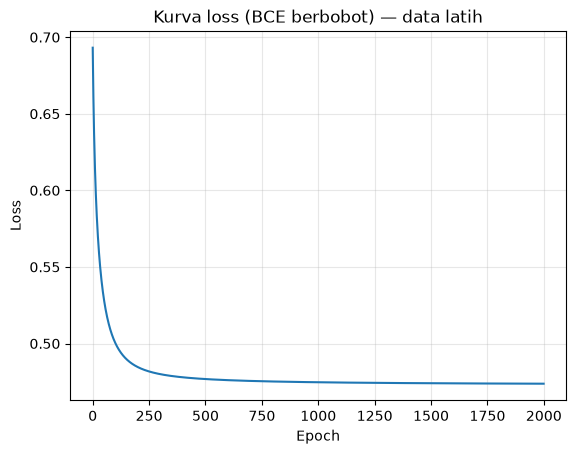

Loss: 0.6931 -> 0.4738


In [18]:
model = LogisticRegression(lr=0.1, epochs=2000, class_weight=True).fit(X_train, y_train)

print(f"Loss awal = {model.riwayat[0]:.4f} | ln 2 = {np.log(2):.4f}")

w0, b0, eps = np.random.default_rng(SEED).normal(0, 0.1, len(FITUR)), 0.1, 1e-5
dw_rumus, _ = model.gradien(X_train, y_train, w0, b0)
dw_numerik = np.array([(model.loss(X_train, y_train, w0 + eps * e, b0) - model.loss(X_train, y_train, w0 - eps * e, b0)) / (2 * eps)
                       for e in np.eye(len(FITUR))])
print(f"Selisih maks gradien rumus vs numerik: {np.max(np.abs(dw_rumus - dw_numerik)):.1e}  (harus sangat kecil)")

plt.plot(model.riwayat)
plt.title('Kurva loss (BCE berbobot) — data latih')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(alpha=0.3)
plt.show()
print(f'Loss: {model.riwayat[0]:.4f} -> {model.riwayat[-1]:.4f}')

**Ketiga bukti lolos.** Loss awal tepat ln 2, gradien rumus sama dengan gradien numerik (selisih ±10⁻¹¹), dan loss turun tajam lalu mendatar di ±0,474 setelah ±750 epoch, artinya training **konvergen**.
Loss tidak mendekati 0, dan itu wajar: data tidak bisa dipisah sempurna (banyak lansia dengan hipertensi yang tidak stroke). Catatan: ini loss *berbobot* (class weight), jadi angkanya tidak bisa dibandingkan langsung dengan loss tanpa class weight.

---
# Modul C — Evaluasi Model
## C.1 Metrik apa yang dipakai, dan kenapa
Ini alat **skrining**: **False Negative** (pasien stroke dibilang aman) **berbahaya**, sedangkan False Positive hanya berarti pemeriksaan tambahan.
Jadi metrik utama adalah **recall** dan **F2** (recall dibobot 2×). Accuracy tetap ditampilkan, tapi bukan acuan. Pembandingnya: **dummy** yang selalu menjawab "tidak stroke".

In [19]:
def evaluasi(y, pred):
    tp, tn = int(np.sum((y == 1) & (pred == 1))), int(np.sum((y == 0) & (pred == 0)))
    fp, fn = int(np.sum((y == 0) & (pred == 1))), int(np.sum((y == 1) & (pred == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    f2 = 5 * precision * recall / (4 * precision + recall) if precision + recall else 0.0
    return {'accuracy': (tp + tn) / len(y), 'precision': precision, 'recall': recall,
            'f1': f1, 'f2': f2, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

cek = evaluasi(np.array([1, 1, 0, 0, 1]), np.array([1, 0, 0, 1, 1]))   # uji manual
print(cek['TP'], cek['FN'], cek['FP'], cek['TN'], '| harusnya 2 1 1 1')

2 1 1 1 | harusnya 2 1 1 1


## C.2 Perbaikan dipilih di data VALIDASI
1. **Class weight**, supaya kelas stroke tidak diabaikan.
2. **Threshold**, dengan aturan yang ditetapkan **sebelum** melihat hasil: *threshold tertinggi yang masih menangkap minimal 80% pasien stroke di validasi (recall ≥ 0,80)*. Target "8 dari 10 pasien stroke tertangkap" mudah dipahami petugas kesehatan, dan threshold tertinggi memberi alarm palsu paling sedikit.

Preprocessor di-*fit* ulang pada *latih-fit* saja, supaya validasi benar-benar "data baru" bagi model.

In [20]:
prep_fit = Preprocessor().fit(fit_df)
X_fit, y_fit = prep_fit.transform(fit_df).values, fit_df[TARGET].values
X_val, y_val = prep_fit.transform(val_df).values, val_df[TARGET].values

model_val = {nama: LogisticRegression(class_weight=cw).fit(X_fit, y_fit)
             for nama, cw in [('Tanpa class weight', False), ('Dengan class weight', True)]}
print('Validasi, threshold 0.5:')
print(pd.DataFrame({nama: evaluasi(y_val, m.predict(X_val)) for nama, m in model_val.items()}).T
      [['accuracy', 'precision', 'recall', 'f2', 'TP', 'FN']].round(3))

Validasi, threshold 0.5:
                     accuracy  precision  recall     f2    TP    FN
Tanpa class weight      0.949       0.00     0.0  0.000   0.0  50.0
Dengan class weight     0.728       0.13     0.8  0.394  40.0  10.0


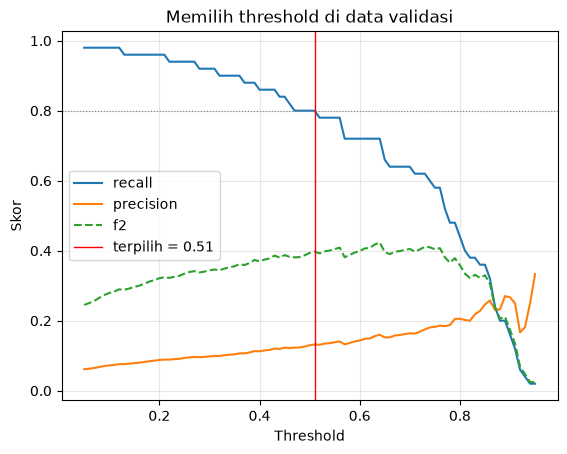

Threshold terpilih: 0.51
           recall  precision     f2   FP
threshold                               
0.30         0.92      0.098  0.344  423
0.40         0.86      0.113  0.369  339
0.50         0.80      0.130  0.394  268
0.51         0.80      0.132  0.398  263
0.64         0.72      0.160  0.424  189
0.70         0.64      0.164  0.405  163


In [21]:
TARGET_RECALL = 0.80
p_val = model_val['Dengan class weight'].predict_proba(X_val)
kurva = pd.DataFrame([{'threshold': t, **evaluasi(y_val, (p_val >= t).astype(int))}
                      for t in np.round(np.arange(0.05, 0.96, 0.01), 2)])
THRESHOLD = float(kurva.loc[kurva['recall'] >= TARGET_RECALL, 'threshold'].max())

for kolom, gaya in [('recall', '-'), ('precision', '-'), ('f2', '--')]:
    plt.plot(kurva['threshold'], kurva[kolom], gaya, label=kolom)
plt.axhline(TARGET_RECALL, color='gray', linewidth=0.8, linestyle=':')
plt.axvline(THRESHOLD, color='red', linewidth=1, label=f'terpilih = {THRESHOLD}')
plt.title('Memilih threshold di data validasi')
plt.xlabel('Threshold')
plt.ylabel('Skor')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Threshold terpilih:', THRESHOLD)
print(kurva.set_index('threshold').loc[sorted({0.3, 0.4, 0.5, THRESHOLD, 0.64, 0.7}), ['recall', 'precision', 'f2', 'FP']].round(3))

**Membaca hasil validasi.**
- **Tanpa class weight, recall 0**: model sama saja dengan dummy. Probabilitasnya tidak pernah melewati 0,5 karena hanya 5% data latih yang stroke.
- **Dengan class weight**: recall langsung naik ke 0,80.
- **Threshold terpilih 0,51**, yaitu threshold tertinggi yang masih memenuhi recall ≥ 0,80.

**Kenapa tidak memilih puncak F2 (0,64)?** Kurva F2 hampir **datar** antara 0,50 dan 0,75 (0,39–0,42), dan selisihnya setara 1–2 pasien, jadi puncaknya bisa saja kebetulan. Selain itu, 0,64 tepat berada di **tepi "jurang"**: sedikit di atasnya recall langsung jatuh dari 0,72 ke 0,66. Threshold di tepi jurang tidak stabil untuk data baru.

## C.3 Model akhir & evaluasi di data uji (SATU kali)
Model akhir = `model` dari B.3 (dilatih di seluruh 80% data latih dengan class weight), dibungkus `StrokeModel` bersama preprocessor dan threshold dari validasi.

In [22]:
stroke_model = StrokeModel(prep, model, THRESHOLD)
model_tanpa = LogisticRegression(class_weight=False).fit(X_train, y_train)

hasil_uji = pd.DataFrame({
    'Dummy (selalu tidak)': evaluasi(y_test, np.zeros(len(y_test), dtype=int)),
    'Sebelum: tanpa class weight, t=0.5': evaluasi(y_test, model_tanpa.predict(X_test)),
    f'Sesudah: class weight, t={THRESHOLD}': evaluasi(y_test, stroke_model.prediksi(test_df)),
}).T
hasil_uji[['accuracy', 'precision', 'recall', 'f1', 'f2', 'TP', 'FN', 'FP', 'TN']].round(3)

,accuracy,precision,recall,f1,f2,TP,FN,FP,TN
Dummy (selalu tidak),0.951,0.000,0.00,0.000,0.000,0.0,50.0,0.0,972.0
"Sebelum: tanpa class weight, t=0.5",0.951,0.500,0.04,0.074,0.049,2.0,48.0,2.0,970.0
"Sesudah: class weight, t=0.51",0.741,0.133,0.78,0.227,0.396,39.0,11.0,254.0,718.0


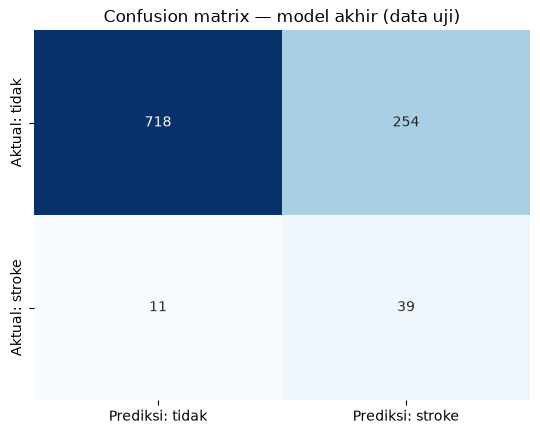

Stroke tertangkap : 39 dari 50 (78%)
Precision alarm   : 13.3% vs rata-rata populasi 4.9%
Lift              : 2.7x lebih tepat daripada memilih pasien secara acak
Perlu cek lanjut  : 293 dari 1022 pasien (29%)


In [23]:
m = hasil_uji.iloc[2]
cm = np.array([[m['TN'], m['FP']], [m['FN'], m['TP']]]).astype(int)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Prediksi: tidak', 'Prediksi: stroke'], yticklabels=['Aktual: tidak', 'Aktual: stroke'])
plt.title('Confusion matrix — model akhir (data uji)')
plt.show()

base_rate = y_test.mean()
print(f"Stroke tertangkap : {int(m['TP'])} dari {int(m['TP'] + m['FN'])} ({m['recall'] * 100:.0f}%)")
print(f"Precision alarm   : {m['precision'] * 100:.1f}% vs rata-rata populasi {base_rate * 100:.1f}%")
print(f"Lift              : {m['precision'] / base_rate:.1f}x lebih tepat daripada memilih pasien secara acak")
print(f"Perlu cek lanjut  : {int(m['TP'] + m['FP'])} dari {len(y_test)} pasien ({(m['TP'] + m['FP']) / len(y_test) * 100:.0f}%)")

**Analisis sebelum vs sesudah.**
- **Sebelum** (tanpa class weight): hanya 2 dari 50 pasien stroke terdeteksi. Accuracy 95% terlihat bagus, padahal **hampir sama dengan dummy**.
- **Sesudah**: **39 dari 50** pasien stroke tertangkap (recall 0,78), F2 naik dari 0,05 ke 0,40. Accuracy turun ke 0,74, dan itu **disengaja**: model sekarang berani memberi alarm.
- **Recall uji (0,78) dekat dengan validasi (0,80)**, jadi threshold tidak "overfit" ke data validasi.
- **Precision 13%**: dari ±7–8 alarm, ±1 benar stroke. Tapi itu **2,7× lebih tepat** daripada memilih pasien secara acak. Konsekuensinya, 29% pasien diminta cek lanjutan. Untuk skrining, ini trade-off yang wajar: lebih baik banyak yang cek daripada pasien stroke terlewat. Kalau fasilitas terbatas, threshold bisa dinaikkan, dan kurva di C.2 menunjukkan berapa recall yang dikorbankan.
- **Ketidakpastian:** data uji hanya punya 50 kasus stroke (1 pasien = 2% recall), jadi angka di atas adalah perkiraan, bukan kepastian.

## C.4 Membaca model: koefisien & odds ratio

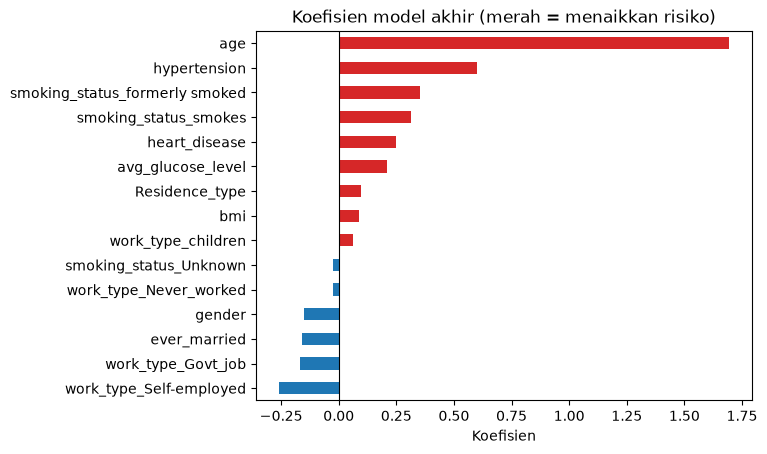

,koefisien,odds_ratio
age,1.695,5.449
hypertension,0.601,1.823
smoking_status_formerly smoked,0.352,1.423
smoking_status_smokes,0.312,1.366
heart_disease,0.247,1.280
avg_glucose_level,0.209,1.232
Residence_type,0.095,1.099
bmi,0.089,1.093
work_type_children,0.060,1.062
smoking_status_Unknown,-0.025,0.975


In [24]:
koef = pd.DataFrame({'koefisien': model.w, 'odds_ratio': np.exp(model.w)}, index=FITUR).sort_values('koefisien')
koef['koefisien'].plot(kind='barh', color=np.where(koef['koefisien'] > 0, 'tab:red', 'tab:blue'))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Koefisien model akhir (merah = menaikkan risiko)')
plt.xlabel('Koefisien')
plt.show()
koef.sort_values('koefisien', ascending=False).round(3)

**Cara membaca:** koefisien fitur numerik berlaku per **1 standar deviasi** (usia ±22,6 tahun, gula darah ±45 mg/dL). Fitur biner/one-hot dibandingkan dengan **pembanding**-nya (perempuan, desa, belum menikah, Private, never smoked). *Odds ratio* = $e^{koefisien}$.

- **Usia** mendominasi: setiap +22,6 tahun, *odds* stroke ×5,4.
- **Hipertensi** ×1,8, **penyakit jantung** ×1,3, **gula darah** ×1,2 per std, **mantan perokok/perokok** ×1,4. Semuanya searah dengan EDA dan pengetahuan medis.
- **`ever_married` negatif (−0,16)**, padahal di EDA "menikah" tampak lebih berisiko. Ini **bukan error**. Ini *confounding* usia (Insight 5): setelah usia masuk ke model, sisa efek menikah kecil dan sedikit berbalik, sama seperti saat kita membandingkan sesama lansia. Hal yang sama berlaku untuk `work_type_Self-employed`.
- Koefisien menunjukkan **asosiasi, bukan sebab-akibat**. Koefisien yang kecil (|koef| < 0,3) praktis berpengaruh lemah.

In [25]:
# Analisis kesalahan: seperti apa pasien stroke yang terlewat?
stroke_uji = test_df[y_test == 1].copy()
stroke_uji['hasil'] = np.where(stroke_model.prediksi(stroke_uji) == 1, 'Terdeteksi (TP)', 'Terlewat (FN)')
stroke_uji.groupby('hasil')[['age', 'avg_glucose_level', 'hypertension', 'heart_disease']].mean().round(2)

,age,avg_glucose_level,hypertension,heart_disease
hasil,,,,
Terdeteksi (TP),73.23,134.31,0.23,0.31
Terlewat (FN),51.45,88.74,0.00,0.00


**Pola kesalahan.** Pasien stroke yang terlewat rata-rata berusia 51 tahun, gula darahnya normal (±89), dan **tidak ada yang punya hipertensi atau penyakit jantung**. Mereka "terlihat sehat" di data. Untuk menangkap mereka dibutuhkan informasi yang tidak ada di dataset ini (kolesterol, riwayat keluarga, tekanan darah dalam angka). Ini **keterbatasan data**, bukan kesalahan kode.

## C.5 Simpan model ke JSON

In [26]:
stroke_model.save('model_stroke_lr.json', fitur=FITUR,
                  metrik_uji={k: float(v) for k, v in m.items()},
                  hyperparameter={'lr': 0.1, 'epochs': 2000, 'split': '80/20 stratified, seed 42'})

model_load = StrokeModel.load('model_stroke_lr.json')     # verifikasi: load ulang -> skor harus sama
print('Tersimpan:', os.path.getsize('model_stroke_lr.json'), 'byte | skor identik setelah load:',
      np.allclose(model_load.skor(test_df), stroke_model.skor(test_df)))

Tersimpan: 2117 byte | skor identik setelah load: True


**Kenapa JSON, bukan pickle?** Bisa dibaca manusia (juri bisa melihat bobotnya), tidak bergantung pada versi Python, dan aman, karena pickle bisa menjalankan kode saat di-load. `save()` menyimpan **bobot + seluruh parameter preprocessing** (`vars(prep)`), dan `load()` membangun ulang ketiga objek dari file itu.

---
# Modul D — Uji Coba Data Baru (GUI)
GUI ada di file terpisah **`gui_stroke_lr.py`**. Jalankan dari terminal: `python gui_stroke_lr.py`
(satu folder dengan `model_lr.py` dan `model_stroke_lr.json`).

- GUI berupa class `AppStroke(tk.Tk)`. Seluruh form dibuat dari **satu daftar `FORM`** lewat loop, jadi tidak ada kode widget yang diulang-ulang.
- GUI memakai `StrokeModel.load()` dari `model_lr.py`, yaitu **class yang sama** dengan notebook. Preprocessing tidak ditulis ulang, sehingga hasilnya pasti identik.
- Kategori memakai **Combobox readonly berbahasa Indonesia**, dan isian angka divalidasi dengan `try/except` + `messagebox`.
- Hasil ditampilkan dengan bahasa awam: **RISIKO TINGGI / Risiko rendah** + skor 0–100 + batas waspada.

In [27]:
from gui_stroke_lr import baca_angka

# 1) Input salah tidak boleh membuat program crash
uji_input = [('', 'Usia', 0, 120), ('abc', 'Usia', 0, 120), ('150', 'Usia', 0, 120),
             ('-5', 'Usia', 0, 120), ('nan', 'Gula darah', 40, 400), ('27,5', 'BMI', 10, 100)]
for teks, nama, lo, hi in uji_input:
    try:
        print(f'{teks!r:8} -> OK, nilai = {baca_angka(teks, nama, lo, hi)}')
    except ValueError as e:
        print(f'{teks!r:8} -> ditolak: {e}')

''       -> ditolak: Usia wajib diisi.
'abc'    -> ditolak: Usia harus berupa angka, bukan "abc".
'150'    -> ditolak: Usia harus di antara 0 dan 120.
'-5'     -> ditolak: Usia harus di antara 0 dan 120.
'nan'    -> ditolak: Gula darah harus di antara 40 dan 400.
'27,5'   -> OK, nilai = 27.5


In [28]:
# 2) Contoh pasien baru, dalam bentuk dict persis seperti yang dikirim GUI
contoh = {
    'Lansia, hipertensi': {'gender': 'Male', 'age': 75, 'hypertension': 1, 'heart_disease': 0,
                           'ever_married': 'Yes', 'work_type': 'Private', 'Residence_type': 'Urban',
                           'avg_glucose_level': 210, 'bmi': 31.0, 'smoking_status': 'formerly smoked'},
    'Dewasa muda sehat': {'gender': 'Female', 'age': 25, 'hypertension': 0, 'heart_disease': 0,
                          'ever_married': 'No', 'work_type': 'Private', 'Residence_type': 'Rural',
                          'avg_glucose_level': 85, 'bmi': None, 'smoking_status': 'never smoked'},
}
for nama, data in contoh.items():
    skor = float(model_load.skor(data)[0])
    label = 'RISIKO TINGGI' if skor >= model_load.threshold else 'Risiko rendah'
    print(f"{nama:20} -> {label} (skor {skor * 100:.0f}/100, batas {model_load.threshold * 100:.0f})")

Lansia, hipertensi   -> RISIKO TINGGI (skor 92/100, batas 51)
Dewasa muda sehat    -> Risiko rendah (skor 7/100, batas 51)


---
## Ringkasan untuk presentasi

In [29]:
print(f"Data        : {len(df)} pasien, stroke hanya {df[TARGET].mean() * 100:.1f}%")
print(f"Model       : Logistic Regression dari nol (OOP), class weight, threshold {THRESHOLD} (dipilih di validasi)")
print(f"Dummy       : accuracy {hasil_uji.iloc[0]['accuracy']:.2f}, recall 0.00")
print(f"Model akhir : recall {m['recall']:.2f} ({int(m['TP'])}/{int(m['TP'] + m['FN'])} stroke tertangkap), "
      f"F2 {m['f2']:.2f}, accuracy {m['accuracy']:.2f}, lift {m['precision'] / base_rate:.1f}x")

Data        : 5109 pasien, stroke hanya 4.9%
Model       : Logistic Regression dari nol (OOP), class weight, threshold 0.51 (dipilih di validasi)
Dummy       : accuracy 0.95, recall 0.00
Model akhir : recall 0.78 (39/50 stroke tertangkap), F2 0.40, accuracy 0.74, lift 2.7x


## Bank pertanyaan juri

| Pertanyaan | Jawaban kuat |
|---|---|
| "Akurasimu 74%, kok lebih jelek dari dummy 95%?" | "Dummy 95% karena stroke cuma 4,9%, tapi recall-nya 0. Model saya menangkap 39 dari 50 pasien stroke. Untuk skrining, yang penting recall." |
| "Kenapa split 80/20, bukan 70/15/15?" | "Stroke hanya 249 kasus. Dengan 80/20, data uji punya 50 kasus (bukan 37), jadi lebih stabil, dan model akhir belajar dari 80% data. Validasi tetap ada, diambil dari data latih." |
| "Kenapa normalisasi? Kenapa z-score?" | "Supaya skala fitur setara dan gradient descent stabil. Z-score dipilih karena min-max sensitif terhadap nilai ekstrem seperti BMI 97,6. Mean dan std dihitung dari data latih saja, itulah yang mencegah leakage." |
| "Turunkan gradien BCE." | "Karena σ'(z) = σ(z)(1−σ(z)), turunan BCE terhadap z menjadi ŷ − y, sehingga ∂L/∂w = Xᵀ(ŷ − y)/N." |
| "Bagaimana kamu tahu training-mu benar?" | "Loss awal = ln 2, gradient check selisihnya ±10⁻¹¹, loss turun lalu konvergen, dan koefisiennya searah dengan EDA." |
| "Kenapa threshold 0,51? Kenapa bukan puncak F2?" | "Aturannya: threshold tertinggi dengan recall validasi ≥ 0,80. Puncak F2 di 0,64 ada di tepi jurang recall dan kurvanya datar, jadi tidak stabil. Buktinya recall uji 0,78, dekat dengan validasi 0,80." |
| "Koefisien `ever_married` negatif, error ya?" | "Bukan. Itu confounding usia: yang menikah rata-rata lebih tua. Setelah usia dikontrol, efeknya kecil dan sedikit berbalik. Koefisien itu asosiasi, bukan sebab-akibat." |
| "Skor 92 artinya peluang stroke 92%?" | "Bukan. Class weight menggeser probabilitas ke atas, jadi skor hanya untuk mengurutkan risiko dan dibandingkan dengan batas. Karena itu GUI menulis 'skor', bukan 'peluang'." |
| "Kenapa JSON, bukan pickle?" | "Bisa dibaca manusia, tidak bergantung pada kode Python, dan aman. Pickle bisa menjalankan kode saat di-load." |

**Keterbatasan:** bukan alat diagnosis; dataset tidak memuat kolesterol, riwayat keluarga, atau tekanan darah dalam angka; data uji hanya 50 kasus stroke; dan data berasal dari luar Indonesia, sehingga threshold perlu dikalibrasi ulang sebelum dipakai di puskesmas.